In [17]:
import numpy as np
import scanpy as sc
import pandas as pd
import numpy as np
from collections import Counter
from scipy import sparse
import anndata as ad
import pickle
import matplotlib.pyplot as plt
from torch import nn
import torch

### preprocessing the Visium data

In [2]:
adata_raw = sc.read_h5ad('../Visium/Visium_FFPE_Human_Breast_Cancer_filtered.h5ad')
adata_raw.var_names_make_unique()
adata = adata_raw
genes_all = adata.var_names
exclude_genes = ('X5S','X5_8S','MT','ENSG','RPS','RPL','AC0','AC1','AC2','AF1','AF2','AL0','AL1','AL3','AL4','AL5','AL6','AL7','AL8','AL9','BX0','BX1','BX2','BX3','BX4','BX5','BX6','AP00','LINC0','RN7S','RNA5S','RNU','RNV','RNA5','SNOR','MIR','SCAR')
genes = [gene for gene in genes_all if (not gene.startswith(exclude_genes))]

print('number of genes before filtering: ', len(genes_all))

print('number of genes after filtering: ', len(genes))

number of genes before filtering:  18085
number of genes after filtering:  17924


/gpfs/gibbs/project/fan/yl2499/conda_envs/iStar/lib/python3.11/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


In [3]:
adata_filtered = adata[:, genes].copy()
adata_filtered.layers['counts'] = adata_filtered.X.copy()
sc.pp.calculate_qc_metrics(adata_filtered, inplace=True)
selected_genes = adata_filtered.var['n_cells_by_counts'] > (adata_filtered.n_vars * 0.15)
adata_filtered = adata_filtered[:, selected_genes].copy()

sc.pp.normalize_total(adata_filtered, target_sum=10000)
# Logarithmize the data
sc.pp.log1p(adata_filtered)
sc.pp.scale(adata_filtered)
sc.pp.highly_variable_genes(adata_filtered, n_top_genes=1000)
#sc.pl.highly_variable_genes(adata_filtered)

adata_filtered_sub = adata_filtered[:, adata_filtered.var['highly_variable']].copy() #adata_filtered.obs['in_tissue']==1
adata_filtered_sub.X = adata_filtered_sub.layers['counts'].copy()

In [4]:
adata_filtered_sub

AnnData object with n_obs × n_vars = 4992 × 1000
    obs: 'in_tissue', 'array_row', 'array_col', 'cluster', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'mean', 'std', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'spatial', 'log1p', 'hvg'
    obsm: 'spatial'
    layers: 'counts'

In [5]:
gene_list1 = adata_filtered_sub.var_names.tolist()

In [6]:
visium_coords = pd.read_csv('../Visium/BreastCancer/spatial/tissue_positions.csv')
visium_coords.index = visium_coords.barcode
visium_coords = visium_coords.loc[adata_filtered_sub.obs_names, :]
visium_coords = visium_coords.rename(columns={'barcode':'Barcode'})
visium_coords = visium_coords.reset_index(drop=True)

In [7]:
visium_coords

,Barcode,in_tissue,array_row,array_col,pxl_row_in_fullres,pxl_col_in_fullres
0,AACACCTACTATCGAA-1,1,0,122,4636,4131
1,AACACGTGCATCGCAC-1,1,76,22,16640,13355
2,AACACTTGGCAAGGAA-1,1,47,71,12067,8845
3,AACAGGAAGAGCATAG-1,1,69,7,15518,14716
4,AACAGGATTCATAGTT-1,1,49,43,12365,11404
...,...,...,...,...,...,...
4987,TGTTGGAACGAGGTCA-1,1,28,72,9049,8731
4988,TGTTGGAAGCTCGGTA-1,1,1,95,4776,6598
4989,TGTTGGATGGACTTCT-1,1,13,53,6653,10447
4990,TGTTGGCCAGACCTAC-1,1,49,47,12368,11039


In [8]:
np.sum(adata_filtered_sub.obs_names == visium_coords.Barcode)

4992

In [9]:
np.sum(np.isnan(visium_coords.pxl_row_in_fullres))

0

In [10]:
spatial_array = np.array([np.array(visium_coords.pxl_col_in_fullres), np.array(visium_coords.pxl_row_in_fullres)]).T
spatial_array.shape

(4992, 2)

In [11]:
adata_filtered_sub.obsm['spatial'] = spatial_array

In [12]:
np.sum(np.isnan(adata_filtered_sub.obsm['spatial']))

0

In [13]:
adata_filtered_sub.obsm['spatial']

array([[ 4131,  4636],
       [13355, 16640],
       [ 8845, 12067],
       ...,
       [10447,  6653],
       [11039, 12368],
       [ 3720, 10518]])

In [14]:
adata_filtered_sub.obs['array_col'] = np.array(visium_coords['array_col'])
adata_filtered_sub.obs['array_row'] = np.array(visium_coords['array_row'])

In [2]:
import sys
import os

# Get the absolute path to the directory containing the script to be imported
script_dir = os.path.abspath("../SuperFocus")

# Add the directory to sys.path
sys.path.append(script_dir)

In [3]:
from importlib import reload
import src.model_training.model_training_orig
import src.model_training.processing_image_features
reload(src.model_training.model_training_orig)
reload(src.model_training.processing_image_features)
from src.model_training.model_training_orig import training_orig

/gpfs/gibbs/project/fan/yl2499/conda_envs/iStar/lib/python3.11/site-packages/torch/cuda/__init__.py:546: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")


In [4]:
sample_id = 'HumanBreastCancer'
he_id = 'Xenium_FFPE_Human_Breast_Cancer_Rep1_he_image_tiled_only'

In [47]:
from catalyst.utils import set_global_seed
set_global_seed(123)
training_orig(adata=adata_filtered_sub, pt_model_dir=f'../CellViT/Visium/preprocessing/{he_id}/{he_id}/cell_detection', radius=50., feature_list=gene_list1, 
              save_model_dir=f'./logs_{sample_id}_reproduce', hidden_dims=[2048, 2048, 1024, 1024], activations=None, residual=False, norm=False, out_act=nn.ReLU(), 
              include_tanhshrink=False, sample_id=sample_id, training_mode='Full_2', selected_model='lite', kfold=5, cell_embed_dir='./Xenium_FFPE_BreastCancer_cellvit_embed.pickle')

/gpfs/gibbs/project/fan/yl2499/conda_envs/iStar/lib/python3.11/site-packages/scanpy/preprocessing/_qc.py:140: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[obs_metrics.columns] = obs_metrics


(3989, 3609)


Detected kernel version 4.18.0, which is below the recommended minimum of 5.5.0; this can cause the process to hang. It is recommended to upgrade the kernel to the minimum version or higher.
/gpfs/gibbs/project/fan/yl2499/conda_envs/iStar/lib/python3.11/site-packages/catalyst/core/misc.py:119: UserWarning: No ``ICriterionCallback/CriterionCallback`` were found while runner.criterion is not None.Do you compute the loss during ``runner.handle_batch``?
  warnings.warn(
/gpfs/gibbs/project/fan/yl2499/conda_envs/iStar/lib/python3.11/site-packages/catalyst/core/misc.py:127: UserWarning: No ``IBackwardCallback/BackwardCallback`` were found while runner.criterion/optimizer is not None.Do you backward the loss during ``runner.handle_batch``?
  warnings.warn(
/gpfs/gibbs/project/fan/yl2499/conda_envs/iStar/lib/python3.11/site-packages/catalyst/core/misc.py:133: UserWarning: No ``IOptimizerCallback/OptimizerCallback`` were found while runner.optimizer is not None.Do run optimisation step pass dur

train (1/50) loss: 1.675584425746834
valid (1/50) loss: 1.3776664267496697
* Epoch (1/50) 
train (2/50) loss: 1.413355565370064
valid (2/50) loss: 1.2961828329939986
* Epoch (2/50) 
train (3/50) loss: 1.3934892145070168
valid (3/50) loss: 1.293940886272138
* Epoch (3/50) 
train (4/50) loss: 1.391684118669982
valid (4/50) loss: 1.2920113609803487
* Epoch (4/50) 
train (5/50) loss: 1.3910504979399676
valid (5/50) loss: 1.2973026955071747
* Epoch (5/50) 
train (6/50) loss: 1.3883131873271306
valid (6/50) loss: 1.28932025473629
* Epoch (6/50) 
train (7/50) loss: 1.3863528378331171
valid (7/50) loss: 1.2865504752115837
* Epoch (7/50) 
train (8/50) loss: 1.3822508564563378
valid (8/50) loss: 1.2854136299452685
* Epoch (8/50) 
train (9/50) loss: 1.3796205348729338
valid (9/50) loss: 1.2860932872515516
* Epoch (9/50) 
train (10/50) loss: 1.3760843704860415
valid (10/50) loss: 1.2749879475863704
* Epoch (10/50) 
train (11/50) loss: 1.3696162409169548
valid (11/50) loss: 1.2670498806545991
* Epo

Detected kernel version 4.18.0, which is below the recommended minimum of 5.5.0; this can cause the process to hang. It is recommended to upgrade the kernel to the minimum version or higher.


valid (50/50) loss: 1.0142950289685961
* Epoch (50/50) 
Top models:
./logs_HumanBreastCancer_reproduce/checkpoints/model.0049.pth	1.0110
train (1/50) loss: 1.0005103342448125
valid (1/50) loss: 0.8996260694949231
* Epoch (1/50) 
train (2/50) loss: 1.000112317633825
valid (2/50) loss: 0.8591109867379956
* Epoch (2/50) 
train (3/50) loss: 0.9907735179930255
valid (3/50) loss: 0.8681737165839695
* Epoch (3/50) 
train (4/50) loss: 0.9904965905175692
valid (4/50) loss: 0.8556414681915954
* Epoch (4/50) 
train (5/50) loss: 0.9896292202247622
valid (5/50) loss: 0.8586561857346082
* Epoch (5/50) 
train (6/50) loss: 0.9829890851735412
valid (6/50) loss: 0.8712983506974009
* Epoch (6/50) 
train (7/50) loss: 0.9856773524297436
valid (7/50) loss: 0.854957951273664
* Epoch (7/50) 
train (8/50) loss: 0.9779763578948348
valid (8/50) loss: 0.8601353979409676
* Epoch (8/50) 
train (9/50) loss: 0.9680037599332743
valid (9/50) loss: 0.850138619588834
* Epoch (9/50) 
train (10/50) loss: 0.9739171719018777

... (2 outputs left out)

Detected kernel version 4.18.0, which is below the recommended minimum of 5.5.0; this can cause the process to hang. It is recommended to upgrade the kernel to the minimum version or higher.


valid (50/50) loss: 0.9291543784933779
* Epoch (50/50) 
Top models:
./logs_HumanBreastCancer_reproduce/checkpoints/model.0001.pth	0.9197
train (1/50) loss: 0.8428291142850683
valid (1/50) loss: 0.9069334130302119
* Epoch (1/50) 
train (2/50) loss: 0.8443690855457323
valid (2/50) loss: 0.8773383296395545
* Epoch (2/50) 
train (3/50) loss: 0.8344861552195134
valid (3/50) loss: 0.8788620028002511
* Epoch (3/50) 
train (4/50) loss: 0.8330555545480589
valid (4/50) loss: 0.8918607081739134
* Epoch (4/50) 
train (5/50) loss: 0.8325032717192635
valid (5/50) loss: 0.8774143136033442
* Epoch (5/50) 
train (6/50) loss: 0.8299257643914814
valid (6/50) loss: 0.8803344770658726
* Epoch (6/50) 
train (7/50) loss: 0.8390748773866008
valid (7/50) loss: 0.9145815871352312
* Epoch (7/50) 
train (8/50) loss: 0.8313475852380579
valid (8/50) loss: 0.8793219111182473
* Epoch (8/50) 
train (9/50) loss: 0.8285523501042052
valid (9/50) loss: 0.8814105828727675
* Epoch (9/50) 
train (10/50) loss: 0.8340936384502

Detected kernel version 4.18.0, which is below the recommended minimum of 5.5.0; this can cause the process to hang. It is recommended to upgrade the kernel to the minimum version or higher.


valid (50/50) loss: 0.8884132528753492
* Epoch (50/50) 
Top models:
./logs_HumanBreastCancer_reproduce/checkpoints/model.0002.pth	0.8773
train (1/50) loss: 0.8382752446907902
valid (1/50) loss: 0.791789164176929
* Epoch (1/50) 
train (2/50) loss: 0.8339064425456492
valid (2/50) loss: 0.796302721231335
* Epoch (2/50) 
train (3/50) loss: 0.8238776005159582
valid (3/50) loss: 0.7892471303386748
* Epoch (3/50) 
train (4/50) loss: 0.8245620080362897
valid (4/50) loss: 0.7907807694333474
* Epoch (4/50) 
train (5/50) loss: 0.8216348044833995
valid (5/50) loss: 0.7916156862596733
* Epoch (5/50) 
train (6/50) loss: 0.8203483410223389
valid (6/50) loss: 0.7886834038088688
* Epoch (6/50) 
train (7/50) loss: 0.8184378394835891
valid (7/50) loss: 0.7910551740831716
* Epoch (7/50) 
train (8/50) loss: 0.8204449827513226
valid (8/50) loss: 0.789266514927616
* Epoch (8/50) 
train (9/50) loss: 0.8212593278135919
valid (9/50) loss: 0.7895013643282708
* Epoch (9/50) 
train (10/50) loss: 0.819996365952669


In [48]:
import src.post_process
from importlib import reload
reload(src.post_process)
from src.post_process import post_training_processing

In [50]:
adata = post_training_processing.post_procesing(model_dir=f'./logs_{sample_id}_reproduce/checkpoints/model.best.pth', hidden_dims=[2048, 2048, 1024, 1024], 
                                               activations=None, out_act=nn.ReLU(), residual=False, norm=False, selected_model='lite', include_tanhshrink=False, 
                                               data_dir=f'./{sample_id}_training_data_level1.pickle', feature_list=gene_list1, datatype='RNA', regress_out=False, resolutions=[0.6, 0.8],
                                               refine_factor=1, sample_id=sample_id, radius=50.)

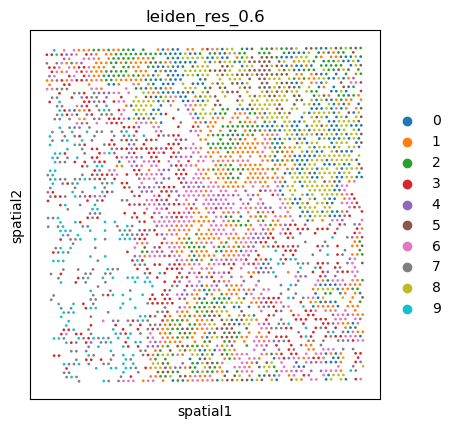

In [51]:
sc.pl.spatial(adata, img_key=None, color='leiden_res_0.6')

In [31]:
import src.model_training.model_training_refined
reload(src.model_training.model_training_refined)
from src.model_training.model_training_refined import training

In [22]:
from catalyst.utils import set_global_seed
set_global_seed(123)
training(adata=adata_filtered_sub, pt_model_dir=f'../CellViT/Visium/preprocessing/{he_id}/{he_id}/cell_detection', radius=50.,
         refine_factor=2, feature_pd_dir=f'./{sample_id}_gene_exp_pd.pickle', 
         trained_model_dir=f'./logs_{sample_id}_reproduce/checkpoints/model.best.pth', 
         save_model_dir=f'./logs_{sample_id}_reproduce_2x', hidden_dims=[2048, 2048, 1024, 1024], activations=None, 
         residual=False, norm=False, out_act=nn.ReLU(), include_tanhshrink=False, sample_id=sample_id, selected_model='lite', 
         training_mode='Full', 
         kfold=5, cell_embed_dir='./Xenium_FFPE_BreastCancer_cellvit_embed.pickle', lr=1e-5, step_size=1000, num_epochs=100)

number of selected original spots in training:  3191
number of selected refined spots in training:  9044

 Fold 1


/gpfs/gibbs/project/fan/yl2499/code/SuperFocus/src/model_training/model_training_refined.py:89: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  gene_counts = preds * torch.tensor(num_cells).unsqueeze(1)


Epoch 1: Validation Loss = 20039.2218
Saved best model for fold 1 at epoch 1
Epoch 2: Validation Loss = 19825.2772
Saved best model for fold 1 at epoch 2
Epoch 3: Validation Loss = 19789.8327
Saved best model for fold 1 at epoch 3
Epoch 4: Validation Loss = 19740.7134
Saved best model for fold 1 at epoch 4
Epoch 5: Validation Loss = 19538.4793
Saved best model for fold 1 at epoch 5
Epoch 6: Validation Loss = 19455.2124
Saved best model for fold 1 at epoch 6
Epoch 7: Validation Loss = 19444.7007
Saved best model for fold 1 at epoch 7
Epoch 8: Validation Loss = 19458.2258
Epoch 9: Validation Loss = 19481.2339
Epoch 10: Validation Loss = 19370.5733
Saved best model for fold 1 at epoch 10
Epoch 11: Validation Loss = 19296.0970
Saved best model for fold 1 at epoch 11
Epoch 12: Validation Loss = 19368.3418
Epoch 13: Validation Loss = 19325.9353
Epoch 14: Validation Loss = 19237.1393
Saved best model for fold 1 at epoch 14
Epoch 15: Validation Loss = 19199.5095
Saved best model for fold 1 at 

Epoch 41: Validation Loss = 15673.8174
Epoch 42: Validation Loss = 14392.2152
Epoch 43: Validation Loss = 14330.2043
Epoch 44: Validation Loss = 17362.7514
Epoch 45: Validation Loss = 12794.3748
Epoch 46: Validation Loss = 15005.2647
Epoch 47: Validation Loss = 13545.6441
Epoch 48: Validation Loss = 13406.4508
Epoch 49: Validation Loss = 14189.7307
Epoch 50: Validation Loss = 13014.9746
Epoch 51: Validation Loss = 13708.9013
Epoch 52: Validation Loss = 16254.7533
Epoch 53: Validation Loss = 11416.4658
Epoch 54: Validation Loss = 16477.2612
Epoch 55: Validation Loss = 14911.1433
Epoch 56: Validation Loss = 12527.9273
Epoch 57: Validation Loss = 14844.7150
Epoch 58: Validation Loss = 13774.6710
Epoch 59: Validation Loss = 13347.4977
Epoch 60: Validation Loss = 15802.8492
Epoch 61: Validation Loss = 17343.0392
Epoch 62: Validation Loss = 14139.7144
Epoch 63: Validation Loss = 19491.8964
Epoch 64: Validation Loss = 16832.6022
Epoch 65: Validation Loss = 13323.2012
Epoch 66: Validation Loss

Epoch 39: Validation Loss = 6435.7159
Epoch 40: Validation Loss = 12856.9185
Epoch 41: Validation Loss = 6655.1275
Epoch 42: Validation Loss = 6398.0539
Epoch 43: Validation Loss = 6049.3814
Epoch 44: Validation Loss = 7165.8063
Epoch 45: Validation Loss = 6752.6356
Epoch 46: Validation Loss = 6493.7519
Epoch 47: Validation Loss = 6769.0683
Epoch 48: Validation Loss = 8872.8103
Epoch 49: Validation Loss = 8096.0394
Epoch 50: Validation Loss = 6815.5651
Epoch 51: Validation Loss = 6885.7361
Epoch 52: Validation Loss = 10116.1306
Epoch 53: Validation Loss = 7136.2558
Epoch 54: Validation Loss = 6955.5733
Epoch 55: Validation Loss = 7145.7013
Epoch 56: Validation Loss = 6899.7667
Epoch 57: Validation Loss = 7957.7409
Epoch 58: Validation Loss = 6480.7000
Epoch 59: Validation Loss = 7262.3233
Epoch 60: Validation Loss = 6291.0877
Epoch 61: Validation Loss = 9369.7429
Epoch 62: Validation Loss = 6648.6160
Epoch 63: Validation Loss = 7178.1386
Epoch 64: Validation Loss = 6649.6031
Epoch 65: 

In [32]:
from catalyst.utils import set_global_seed
set_global_seed(123)
training(adata=adata_filtered_sub, pt_model_dir=f'../CellViT/Visium/preprocessing/{he_id}/{he_id}/cell_detection', radius=50.,
         refine_factor=4, feature_pd_dir=f'./{sample_id}_gene_exp_pd.pickle', 
         trained_model_dir=f'./logs_{sample_id}_reproduce_2x/best_model_fold5.pth', 
         save_model_dir=f'./logs_{sample_id}_reproduce_4x', hidden_dims=[2048, 2048, 1024, 1024], activations=None, 
         residual=False, norm=False, out_act=nn.ReLU(), include_tanhshrink=False, sample_id=sample_id, selected_model='lite', 
         training_mode='Full', 
         kfold=5, cell_embed_dir='./Xenium_FFPE_BreastCancer_cellvit_embed.pickle', lr=1e-6, step_size=30, gamma=0.5, num_epochs=50, random_state=42, sort_way='row_col')

number of selected original spots in training:  3191
number of selected refined spots in training:  19890

 Fold 1


/gpfs/gibbs/project/fan/yl2499/code/SuperFocus/src/model_training/model_training_refined.py:89: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  gene_counts = preds * torch.tensor(num_cells).unsqueeze(1)


Epoch 1: Validation Loss = 8503.6474
Saved best model for fold 1 at epoch 1
Epoch 2: Validation Loss = 8286.2818
Saved best model for fold 1 at epoch 2
Epoch 3: Validation Loss = 8192.8996
Saved best model for fold 1 at epoch 3
Epoch 4: Validation Loss = 8137.7667
Saved best model for fold 1 at epoch 4
Epoch 5: Validation Loss = 8107.9743
Saved best model for fold 1 at epoch 5
Epoch 6: Validation Loss = 8091.2848
Saved best model for fold 1 at epoch 6
Epoch 7: Validation Loss = 8079.1085
Saved best model for fold 1 at epoch 7
Epoch 8: Validation Loss = 8069.0470
Saved best model for fold 1 at epoch 8
Epoch 9: Validation Loss = 8059.4364
Saved best model for fold 1 at epoch 9
Epoch 10: Validation Loss = 8054.4012
Saved best model for fold 1 at epoch 10
Epoch 11: Validation Loss = 8051.8367
Saved best model for fold 1 at epoch 11
Epoch 12: Validation Loss = 8051.2619
Saved best model for fold 1 at epoch 12
Epoch 13: Validation Loss = 8051.0294
Saved best model for fold 1 at epoch 13
Epoc

Epoch 49: Validation Loss = 6743.3873
Epoch 50: Validation Loss = 6744.0138

 Fold 5
Epoch 1: Validation Loss = 6629.6821
Saved best model for fold 5 at epoch 1
Epoch 2: Validation Loss = 6630.3882
Epoch 3: Validation Loss = 6631.3058
Epoch 4: Validation Loss = 6632.2878
Epoch 5: Validation Loss = 6633.2620
Epoch 6: Validation Loss = 6634.2694
Epoch 7: Validation Loss = 6635.2821
Epoch 8: Validation Loss = 6636.2414
Epoch 9: Validation Loss = 6637.1709
Epoch 10: Validation Loss = 6638.1221
Epoch 11: Validation Loss = 6637.6016
Epoch 12: Validation Loss = 6637.5357
Epoch 13: Validation Loss = 6637.7433
Epoch 14: Validation Loss = 6638.0648
Epoch 15: Validation Loss = 6638.4319
Epoch 16: Validation Loss = 6638.8368
Epoch 17: Validation Loss = 6639.2515
Epoch 18: Validation Loss = 6639.6792
Epoch 19: Validation Loss = 6640.1101
Epoch 20: Validation Loss = 6640.5354
Epoch 21: Validation Loss = 6640.9640
Epoch 22: Validation Loss = 6641.3893
Epoch 23: Validation Loss = 6641.8185
Epoch 24: V

In [33]:
from catalyst.utils import set_global_seed
set_global_seed(123)
training(adata=adata_filtered_sub, pt_model_dir=f'../CellViT/Visium/preprocessing/{he_id}/{he_id}/cell_detection', radius=50.,
         refine_factor=8, feature_pd_dir=f'./{sample_id}_gene_exp_pd.pickle', 
         trained_model_dir=f'./logs_{sample_id}_reproduce_4x/best_model_fold2.pth', 
         save_model_dir=f'./logs_{sample_id}_reproduce_8x', hidden_dims=[2048, 2048, 1024, 1024], activations=None, 
         residual=False, norm=False, out_act=nn.ReLU(), include_tanhshrink=False, sample_id=sample_id, selected_model='lite', 
         training_mode='Full', 
         kfold=5, cell_embed_dir='./Xenium_FFPE_BreastCancer_cellvit_embed.pickle', lr=1e-7, step_size=20, gamma=0.1, num_epochs=50, random_state=42, sort_way='row_col')

number of selected original spots in training:  3191
number of selected refined spots in training:  27650

 Fold 1


/gpfs/gibbs/project/fan/yl2499/code/SuperFocus/src/model_training/model_training_refined.py:89: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  gene_counts = preds * torch.tensor(num_cells).unsqueeze(1)


Epoch 1: Validation Loss = 10949.9917
Saved best model for fold 1 at epoch 1
Epoch 2: Validation Loss = 10704.0241
Saved best model for fold 1 at epoch 2
Epoch 3: Validation Loss = 10516.8036
Saved best model for fold 1 at epoch 3
Epoch 4: Validation Loss = 10359.6823
Saved best model for fold 1 at epoch 4
Epoch 5: Validation Loss = 10227.2111
Saved best model for fold 1 at epoch 5
Epoch 6: Validation Loss = 10114.4961
Saved best model for fold 1 at epoch 6
Epoch 7: Validation Loss = 10019.6115
Saved best model for fold 1 at epoch 7
Epoch 8: Validation Loss = 9936.9505
Saved best model for fold 1 at epoch 8
Epoch 9: Validation Loss = 9868.5749
Saved best model for fold 1 at epoch 9
Epoch 10: Validation Loss = 9811.2189
Saved best model for fold 1 at epoch 10
Epoch 11: Validation Loss = 9762.4372
Saved best model for fold 1 at epoch 11
Epoch 12: Validation Loss = 9722.1254
Saved best model for fold 1 at epoch 12
Epoch 13: Validation Loss = 9687.5179
Saved best model for fold 1 at epoch 

Epoch 26: Validation Loss = 11072.0530
Epoch 27: Validation Loss = 11072.0530
Epoch 28: Validation Loss = 11072.0530
Epoch 29: Validation Loss = 11072.0530
Epoch 30: Validation Loss = 11072.0530
Epoch 31: Validation Loss = 11072.0530
Epoch 32: Validation Loss = 11072.0530
Epoch 33: Validation Loss = 11072.0530
Epoch 34: Validation Loss = 11072.0530
Epoch 35: Validation Loss = 11072.0530
Epoch 36: Validation Loss = 11072.0530
Epoch 37: Validation Loss = 11072.0530
Epoch 38: Validation Loss = 11072.0530
Epoch 39: Validation Loss = 11072.0530
Epoch 40: Validation Loss = 11072.0530
Epoch 41: Validation Loss = 11072.0530
Epoch 42: Validation Loss = 11072.0530
Epoch 43: Validation Loss = 11072.0530
Epoch 44: Validation Loss = 11072.0530
Epoch 45: Validation Loss = 11072.0530
Epoch 46: Validation Loss = 11072.0530
Epoch 47: Validation Loss = 11072.0530
Epoch 48: Validation Loss = 11072.0530
Epoch 49: Validation Loss = 11072.0530
Epoch 50: Validation Loss = 11072.0530

 Fold 5
Epoch 1: Validat

### apply it to whole tissue slide

In [5]:
from src.model_training.processing_image_features import whole_image_all_cells_features
from src.model_training import MLP

In [6]:
refine_factor = 8

In [7]:
cell_markers, cell_counts, cell_coords = whole_image_all_cells_features(pt_model_dir=f'../../CellViT/Visium/preprocessing/{he_id}/{he_id}/cell_detection', radius=50./refine_factor, cell_embed_dir='../Xenium_FFPE_BreastCancer_cellvit_embed.pickle')

In [9]:
cellvit_marker_array = np.hstack((cell_markers, cell_counts))

In [10]:
with open(f'../{sample_id}_scaler_refine_level{refine_factor}.pickle', 'rb') as file:
    CODEX_HIST_scaler = pickle.load(file)
    
with open(f'../{sample_id}_gene_exp_pd.pickle', 'rb') as file:
    dbit_pd = pickle.load(file)

In [12]:
codex_cell_marker_scaled = CODEX_HIST_scaler.transform(cellvit_marker_array)

In [13]:
hidden_dims=[2048, 2048, 1024, 1024]
activations=None
residual=False
norm=False
out_act=nn.ReLU()
model = MLP.Model_lite(n_inp=3609, n_out=1000, hidden_dims=hidden_dims, activations=activations, out_activation=out_act)

In [31]:
state_dict = torch.load(f'../logs_{sample_id}_reproduce_8x/best_model_fold1.pth', map_location=torch.device('cpu')) # Load on CPU
model.load_state_dict(state_dict)

<All keys matched successfully>

In [32]:
model.eval()

with torch.no_grad():
    output_full = model(torch.tensor(codex_cell_marker_scaled).to(torch.float32))

In [33]:
predicted_gene_full= np.array(output_full) * cell_counts[:, 0][:, None]
predicted_gene_full = np.maximum(0, predicted_gene_full)

## Create adata object
adata = ad.AnnData(predicted_gene_full)#ad.AnnData(sparse.csc_matrix(predicted_gene))

#adata.obs_names = list(dbit_pd.index)
adata.var_names = list(dbit_pd.columns)

adata.obs['x'] = np.array(cell_coords['pxl_col_in_fullres'])
adata.obs['y'] = np.array(cell_coords['pxl_row_in_fullres'])
adata.obs['section_id'] = [he_id]*adata.n_obs

adata.layers['counts'] = predicted_gene_full.copy()

In [34]:
adata.uns = {}
adata.uns['spatial'] = {}
adata.uns['spatial'][sample_id] = {}
adata.uns['spatial'][sample_id]['images'] = {}
#adata_query.uns['spatial'][sample_id]['images']['lowres'] = imageLN_flip # rotated_imageLN
adata.uns['spatial'][sample_id]['scalefactors'] = {}
adata.uns['spatial'][sample_id]['scalefactors']['tissue_hires_scalef'] = 16.0  # 78.5
adata.uns['spatial'][sample_id]['scalefactors']['spot_diameter_fullres'] =  20.0 #2.18
adata.uns['spatial'][sample_id]['scalefactors']['fiducial_diameter_fullres'] = 4.24
adata.uns['spatial'][sample_id]['scalefactors']['tissue_lowres_scalef'] = 16.0 # 78.5

adata.obsm['spatial'] = np.array([adata.obs['x'], adata.obs['y']]).T
adata.obs['sample_id'] = [he_id] * adata.n_obs

/gpfs/gibbs/project/fan/yl2499/conda_envs/iStar/lib/python3.11/site-packages/scanpy/preprocessing/_qc.py:431: RuntimeWarning: invalid value encountered in divide
  return values / sums[:, None]
/gpfs/gibbs/project/fan/yl2499/conda_envs/iStar/lib/python3.11/site-packages/scanpy/preprocessing/_normalization.py:233: UserWarning: Some cells have zero counts
  warn(UserWarning("Some cells have zero counts"))


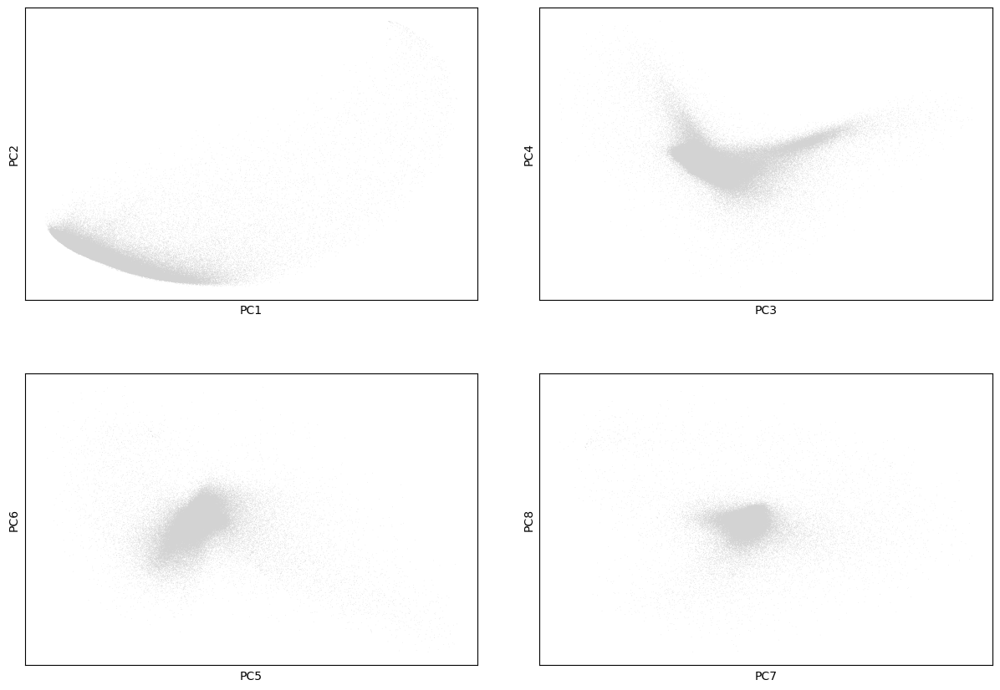

In [35]:
sc.pp.calculate_qc_metrics(adata, inplace=True, log1p=True)
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
#sc.pp.highly_variable_genes(adata, n_top_genes=2000)

# scale data, clip values exceeding standard deviation 10.
sc.pp.scale(adata, max_value=10)

sc.tl.pca(adata, svd_solver='arpack')
# plot more PCS
sc.pl.pca(adata, components = ['1,2','3,4','5,6','7,8'], ncols=2)

In [36]:
# Then we calculate a new umap
sc.pp.neighbors(adata, n_neighbors=100, n_pcs=20, use_rep='X_pca', random_state=0)

sc.tl.umap(adata, random_state=0)

sc.tl.leiden(adata, resolution = 0.6, key_added = "leiden_0.6", random_state=0, flavor='igraph', n_iterations=2)

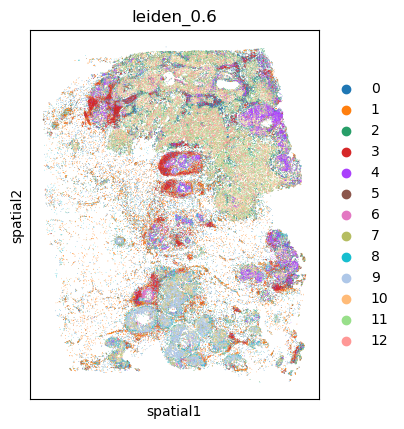

In [38]:
sc.pl.spatial(adata, img_key=None, color='leiden_0.6', size=1.5) 

In [45]:
celltype = np.array(adata.obs['leiden_0.6'])
celltype[adata.obs['leiden_0.6'] == '0'] = "Stromal"
celltype[adata.obs['leiden_0.6'] == '1'] = "Stromal"
celltype[adata.obs['leiden_0.6'] == '2'] = "Endothelial"
celltype[adata.obs['leiden_0.6'] == '3'] = "Immune_Cells"
celltype[adata.obs['leiden_0.6'] == '4'] = "DCIS_2"
celltype[adata.obs['leiden_0.6'] == '5'] = "Stromal"
celltype[adata.obs['leiden_0.6'] == '6'] = "Myoepi"
celltype[adata.obs['leiden_0.6'] == '7'] = "Immune_Cells" #"DCIS_2"
celltype[adata.obs['leiden_0.6'] == '8'] = "Myoepi"
celltype[adata.obs['leiden_0.6'] == '9'] = "DCIS_1"
celltype[adata.obs['leiden_0.6'] == '10'] = "Invasive_Tumor"
celltype[adata.obs['leiden_0.6'] == '11'] = "Invasive_Tumor"
celltype[adata.obs['leiden_0.6'] == '12'] = "Prolif_Invasive_Tumor"
adata.obs['celltype'] = celltype

In [41]:
color_list = ['#1f77b4', '#abddde', '#d7ef9b', '#2ca02c', '#cc66ff', '#ffff0a', '#b487b7',
       '#ff7f0e']
adata.uns['celltype_colors'] = color_list

In [43]:
sc.pp.neighbors(adata, n_neighbors=100, n_pcs=20, use_rep='X_pca', random_state=0)
sc.tl.umap(adata, min_dist=0.0, random_state=0)

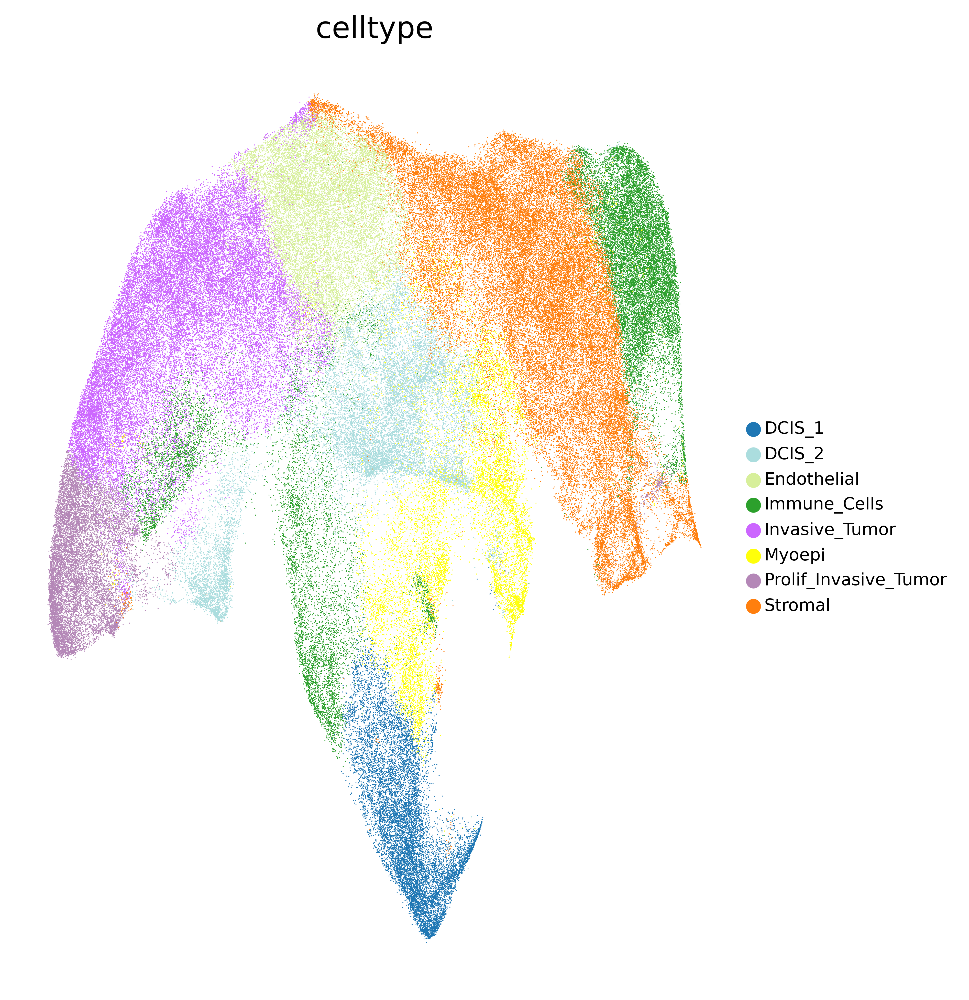

In [46]:
sc.set_figure_params(
    figsize=(6, 8), 
    dpi=300, 
    dpi_save=300, 
    frameon=False
)
sc.pl.umap(adata, color=['celltype'], legend_fontsize=8, size=1.0)

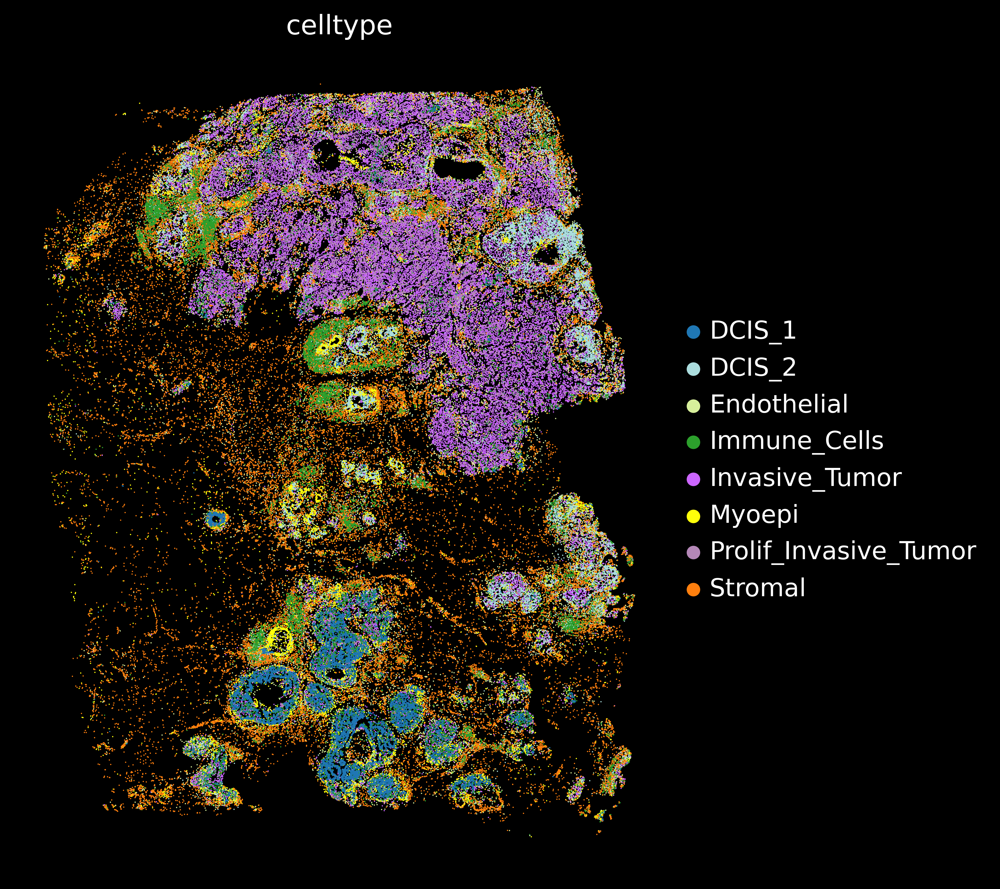

In [49]:
plt.style.use('dark_background')
sc.pl.spatial(adata, img_key=None, color='celltype', size=1.5, frameon=False) 

### Xenium genes

In [52]:
hidden_dims=[2048, 2048, 1024, 1024]
activations=None
residual=False
norm=False
out_act=nn.ReLU()
model = MLP.Model_lite(n_inp=3609, n_out=313, hidden_dims=hidden_dims, activations=activations, out_activation=out_act)

In [50]:
state_dict = torch.load('../logs_all_genes_xenium_visium_counts_normal_xenium_genes_8x/best_model_fold3.pth', map_location=torch.device('cpu')) # Load on CPU

In [53]:
model.load_state_dict(state_dict)

<All keys matched successfully>

In [67]:
with open(f'../{sample_id}_xenium_gene_model_scaler.pickle', 'rb') as file:
    CODEX_HIST_scaler = pickle.load(file)

In [68]:
codex_cell_marker_scaled = CODEX_HIST_scaler.transform(cellvit_marker_array)

In [69]:
model.eval()

with torch.no_grad():
    output_full = model(torch.tensor(codex_cell_marker_scaled).to(torch.float32))

In [70]:
with open('../Xenium_Visium_FFPE_BreastCancer_xenium_gene_exp_pd.pickle', 'rb') as handle:
    dbit_pd = pickle.load(handle)

In [71]:
predicted_gene_full= np.array(output_full) * cell_counts[:, 0][:, None]
predicted_gene_full = np.maximum(0, predicted_gene_full)

## Create adata object
adata = ad.AnnData(predicted_gene_full)#ad.AnnData(sparse.csc_matrix(predicted_gene))

#adata.obs_names = list(dbit_pd.index)
adata.var_names = list(dbit_pd.columns)

adata.obs['x'] = np.array(cell_coords['pxl_col_in_fullres'])
adata.obs['y'] = np.array(cell_coords['pxl_row_in_fullres'])
adata.obs['section_id'] = [he_id]*adata.n_obs

adata.layers['counts'] = adata.X.copy()

In [83]:
xenium_data = sc.read_h5ad('../DBiT_imputation-CellViT-Xenium-FFPE-BreastCancer-original_annotated_withHE.h5ad')

In [84]:
xenium_data

AnnData object with n_obs × n_vars = 167780 × 313
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'region', 'celltype'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'celltype_colors', 'log1p', 'spatial', 'spatialdata_attrs'
    obsm: 'spatial', 'spatial_HE', 'spatial_orig'
    layers: 'counts'

In [74]:
## load corrdinates aligned to zenium data
with open('../FFPE_BreastCancer_Xneium_HE_STAlign_50_coords.pickle', 'rb') as handle:
    xI, yI, xI_LDDMM, yI_LDDMM = pickle.load(handle)

In [79]:
adata.obs['x_aligned']= xI_LDDMM
adata.obs['y_aligned']= yI_LDDMM
adata.obs['celltype']= celltype

In [80]:
## get the overlapping area
min_xI = np.max((np.min(xI_LDDMM), np.min(xenium_data.obsm['spatial'][:, 0])))
max_xI = np.min((np.max(xI_LDDMM), np.max(xenium_data.obsm['spatial'][:, 0])))
min_yI = np.max((np.min(yI_LDDMM), np.min(xenium_data.obsm['spatial'][:, 1])))
max_yI = np.min((np.max(yI_LDDMM), np.max(xenium_data.obsm['spatial'][:, 1])))

selected_genes = [gene for gene in adata.var_names if gene in xenium_data.var_names]
adata_sub = adata[(xI_LDDMM >= min_xI) * (xI_LDDMM <= max_xI) * (yI_LDDMM >= min_yI) * (yI_LDDMM <= max_yI), selected_genes].copy()
adata_sub

AnnData object with n_obs × n_vars = 128500 × 313
    obs: 'x', 'y', 'section_id', 'x_aligned', 'y_aligned', 'celltype'
    layers: 'counts'

In [81]:
adata_sub.obsm['spatial_aligned'] = np.array([adata_sub.obs['x_aligned'], adata_sub.obs['y_aligned']]).T

In [ ]:
adata_sub.write_h5ad('./FFPE_BreastCancer_Xneium_predicted_aligned.h5ad')

In [122]:
xenium_data_sub = xenium_data[(xenium_data.obsm['spatial_orig'][:, 0] >= min_xI) * (xenium_data.obsm['spatial_orig'][:, 0] <= max_xI) * (xenium_data.obsm['spatial_orig'][:, 1] >= min_yI) * (xenium_data.obsm['spatial_orig'][:, 1] <= max_yI), selected_genes].copy()
xenium_data_sub

AnnData object with n_obs × n_vars = 167780 × 313
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'region', 'celltype'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'celltype_colors', 'log1p', 'spatial', 'spatialdata_attrs'
    obsm: 'spatial', 'spatial_HE', 'spatial_orig'
    layers: 'counts'

In [ ]:
xenium_data_sub.write_h5ad('./FFPE_BreastCancer_Xenium_matched.h5ad')

In [87]:
std_pred = np.std(np.array(adata_sub.X), axis=0)
genes_include = adata_sub.var_names[np.where(std_pred!=0)[0]]

In [88]:
xenium_data_sub_selected_sub = xenium_data_sub[xenium_data_sub.obs['celltype']!='Unknown_or_Other_Cells', genes_include].copy()
adata_selected_sub = adata_sub[:, genes_include].copy()

#### gene heatmap

In [89]:
sc.tl.rank_genes_groups(xenium_data_sub_selected_sub, groupby='celltype')

clusters_order = ['DCIS_1', 'DCIS_2', 'Endothelial', 'Immune_Cells', 'Invasive_Tumor', 'Myoepi', 'Prolif_Invasive_Tumor', 'Stromal']
lg_list = []
for lk in clusters_order:
    genes = list(sc.get.rank_genes_groups_df(xenium_data_sub_selected_sub, group=lk, pval_cutoff=0.05, log2fc_min=1.5).names.values)
    lg_list += genes

In [90]:
def grouped_obs_mean(adata, group_key, layer=None, gene_symbols=None):
    if layer is not None:
        getX = lambda x: x.layers[layer]
    else:
        getX = lambda x: x.X
    if gene_symbols is not None:
        new_idx = adata.var[idx]
    else:
        new_idx = adata.var_names

    grouped = adata.obs.groupby(group_key)
    out = pd.DataFrame(
        np.zeros((adata.shape[1], len(grouped)), dtype=np.float64),
        columns=list(grouped.groups.keys()),
        index=adata.var_names
    )

    for group, idx in grouped.indices.items():
        X = getX(adata[idx])
        out[group] = np.ravel(X.mean(axis=0, dtype=np.float64))
    return out

In [91]:
adata_cluster_mean = grouped_obs_mean(adata_selected_sub, 'celltype')
xenium_cluster_mean = grouped_obs_mean(xenium_data_sub_selected_sub, 'celltype')

/tmp/ipykernel_137643/1302019431.py:11: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped = adata.obs.groupby(group_key)


[]

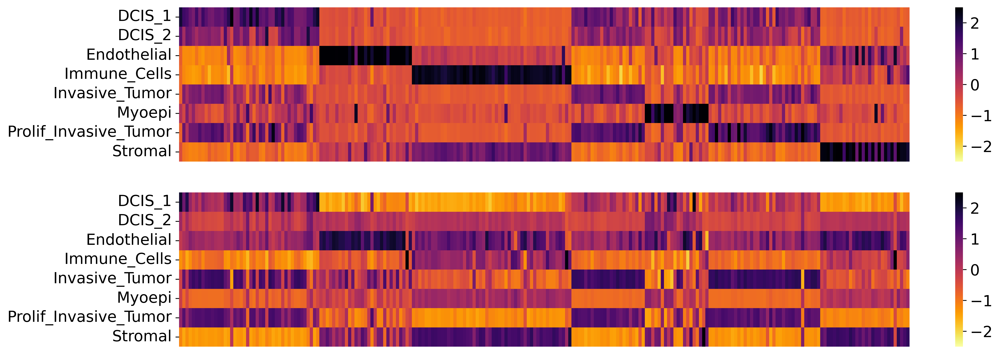

In [94]:
from scipy.stats import zscore
import seaborn as sns
plt.style.use('default')
fig, axes = plt.subplots(figsize=(16, 6), nrows=2, dpi=300)
sns.heatmap(xenium_cluster_mean.loc[lg_list, clusters_order].T.apply(zscore), cmap="inferno_r", ax=axes[0], xticklabels = 3, vmax=2.5, vmin=-2.5)
sns.heatmap(adata_cluster_mean.loc[lg_list, clusters_order].T.apply(zscore), cmap="inferno_r", ax=axes[1], xticklabels = 3, vmax=2.5, vmin=-2.5)

# Hide grid lines
axes[0].grid(False)
axes[1].grid(False)

axes[0].set_yticklabels(axes[0].get_yticklabels(), size=15)
axes[1].set_yticklabels(axes[1].get_yticklabels(), size=15)

axes[0].collections[0].colorbar.ax.tick_params(labelsize=15)
axes[1].collections[0].colorbar.ax.tick_params(labelsize=15)

# Hide axes ticks
axes[0].set_xticks([])
axes[1].set_xticks([])

#### MS-SSIM

In [100]:
import numpy as np
import pandas as pd

from matplotlib import pyplot as plt
import json 
import scanpy as sc 
from PIL import Image
import cv2
from shapely import geometry
from shapely.geometry import Polygon
import rasterio.features
from scipy.sparse import issparse

import os
import argparse
import sys

# Get the absolute path to the directory containing the script to be imported
script_dir = os.path.abspath("/gpfs/ycga/work/fan/yl2499/istar")
# Add the directory to sys.path
sys.path.append(script_dir)
from iStar.utils import load_image
from iStar.plot_imputed import plot_super

In [101]:
def get_adata_layer(adata, layer_key=None):
    cnts = adata.X if layer_key is None else adata.layers[layer_key]
    return cnts


def get_adata_layer_array(adata, layer_key=None):
    cnts = get_adata_layer(adata, layer_key=layer_key)

    if issparse(cnts):
        cnts = cnts.toarray()

    return cnts


def rescale(value, scalefactor):
    return int(np.round(value*scalefactor))

def resize_array(arr, target_shape, interpolation=cv2.INTER_LINEAR):
    import cv2
    return cv2.resize(arr, target_shape, interpolation=interpolation) 

def get_downscaled_im(gene_array, scalefactor, locs, image_size):
    xmin, ymin = 1, 1
    xmax, ymax = image_size

    grid_sizes = (rescale(ymax, scalefactor), rescale(xmax, scalefactor))
    grid_values = np.zeros(grid_sizes)

    # Populate the grid with values from the spatial data
    x = locs[:, 0]
    y = locs[:, 1]

    col_index = np.digitize(x, np.linspace(xmin, xmax, grid_sizes[1])).astype(int).reshape(-1, 1)
    row_index = np.digitize(y, np.linspace(ymin, ymax, grid_sizes[0])).astype(int).reshape(-1, 1)

    # Assign the value to the corresponding grid cell
    if issparse(gene_array):
        grid_values[row_index - 1, col_index - 1] += gene_array[:, 0]
    else:
        grid_values[row_index - 1, col_index - 1] += gene_array
    

    grid_values[grid_values < 0] = 0
    return grid_values

def get_downscaled_roi_im(gene, ad, image_size, scalefactor, key_word = 'spatial', roi=None):
    gene_array = get_adata_layer_array(ad[:, gene])
    #scalefactor = get_scalefactors(ad)['tissue_hires_scalef']
    locs = ad.obsm[key_word]
    
    grid_values = get_downscaled_im(gene_array, scalefactor, locs, image_size)

    if roi is None:
        return grid_values
    
    roi_downscale = (rescale(roi[2], scalefactor), rescale(roi[3], scalefactor), rescale(roi[0], scalefactor), rescale(roi[1],scalefactor))
    gene_mat_roi = grid_values[roi_downscale[0]: roi_downscale[1], roi_downscale[2]:roi_downscale[3]]
    
    return gene_mat_roi

In [113]:
output_dir = "BreastCancer"
xen_output_dir = os.path.join(output_dir, "Xenium_nongrid_64")
os.makedirs(xen_output_dir, exist_ok=True)

xenium_grid_data = xenium_data

for gene in xenium_grid_data.var_names:
    xenium_gene_exp = xenium_grid_data[:, gene].X.copy()
    xenium_gene_grid = get_downscaled_im(xenium_gene_exp, 1/4, xenium_grid_data.obsm['spatial_orig'], (7523, 5476))
    plot_super(xenium_gene_grid, os.path.join(xen_output_dir, f'{gene}.png'))

BreastCancer/Xenium_nongrid_64/ABCC11.png
BreastCancer/Xenium_nongrid_64/ACTA2.png
BreastCancer/Xenium_nongrid_64/ACTG2.png
BreastCancer/Xenium_nongrid_64/ADAM9.png
BreastCancer/Xenium_nongrid_64/ADGRE5.png
BreastCancer/Xenium_nongrid_64/ADH1B.png
BreastCancer/Xenium_nongrid_64/ADIPOQ.png
BreastCancer/Xenium_nongrid_64/AGR3.png
BreastCancer/Xenium_nongrid_64/AHSP.png
BreastCancer/Xenium_nongrid_64/AIF1.png
BreastCancer/Xenium_nongrid_64/AKR1C1.png
BreastCancer/Xenium_nongrid_64/AKR1C3.png
BreastCancer/Xenium_nongrid_64/ALDH1A3.png
BreastCancer/Xenium_nongrid_64/ANGPT2.png
BreastCancer/Xenium_nongrid_64/ANKRD28.png
BreastCancer/Xenium_nongrid_64/ANKRD29.png
BreastCancer/Xenium_nongrid_64/ANKRD30A.png
BreastCancer/Xenium_nongrid_64/APOBEC3A.png
BreastCancer/Xenium_nongrid_64/APOBEC3B.png
BreastCancer/Xenium_nongrid_64/APOC1.png
BreastCancer/Xenium_nongrid_64/AQP1.png
BreastCancer/Xenium_nongrid_64/AQP3.png
BreastCancer/Xenium_nongrid_64/AR.png
BreastCancer/Xenium_nongrid_64/AVPR1A.png
Br

BreastCancer/Xenium_nongrid_64/MYBPC1.png
BreastCancer/Xenium_nongrid_64/MYH11.png
BreastCancer/Xenium_nongrid_64/MYLK.png
BreastCancer/Xenium_nongrid_64/MYO5B.png
BreastCancer/Xenium_nongrid_64/MZB1.png
BreastCancer/Xenium_nongrid_64/NARS.png
BreastCancer/Xenium_nongrid_64/NCAM1.png
BreastCancer/Xenium_nongrid_64/NDUFA4L2.png
BreastCancer/Xenium_nongrid_64/NKG7.png
BreastCancer/Xenium_nongrid_64/NOSTRIN.png
BreastCancer/Xenium_nongrid_64/NPM3.png
BreastCancer/Xenium_nongrid_64/OCIAD2.png
BreastCancer/Xenium_nongrid_64/OPRPN.png
BreastCancer/Xenium_nongrid_64/OXTR.png
BreastCancer/Xenium_nongrid_64/PCLAF.png
BreastCancer/Xenium_nongrid_64/PCOLCE.png
BreastCancer/Xenium_nongrid_64/PDCD1.png
BreastCancer/Xenium_nongrid_64/PDCD1LG2.png
BreastCancer/Xenium_nongrid_64/PDE4A.png
BreastCancer/Xenium_nongrid_64/PDGFRA.png
BreastCancer/Xenium_nongrid_64/PDGFRB.png
BreastCancer/Xenium_nongrid_64/PDK4.png
BreastCancer/Xenium_nongrid_64/PECAM1.png
BreastCancer/Xenium_nongrid_64/PELI1.png
BreastCan

In [104]:
output_dir = "BreastCancer"
xen_output_dir = os.path.join(output_dir, "SuperFocus_64")
os.makedirs(xen_output_dir, exist_ok=True)

xenium_grid_data = adata_sub

for gene in xenium_grid_data.var_names:
    xenium_gene_exp = xenium_grid_data[:, gene].X.copy()
    xenium_gene_grid = get_downscaled_im(xenium_gene_exp, 1/4, xenium_grid_data.obsm['spatial_aligned'], (7523, 5476))
    plot_super(xenium_gene_grid, os.path.join(xen_output_dir, f'{gene}.png'))

BreastCancer/SuperFocus_64/FBLIM1.png
BreastCancer/SuperFocus_64/C1QA.png
BreastCancer/SuperFocus_64/C1QC.png
BreastCancer/SuperFocus_64/TRAPPC3.png
BreastCancer/SuperFocus_64/SMAP2.png
BreastCancer/SuperFocus_64/TACSTD2.png
BreastCancer/SuperFocus_64/CTH.png
BreastCancer/SuperFocus_64/CLCA2.png
BreastCancer/SuperFocus_64/TENT5C.png
BreastCancer/SuperFocus_64/RORC.png
BreastCancer/SuperFocus_64/S100A8.png
BreastCancer/SuperFocus_64/S100A4.png
BreastCancer/SuperFocus_64/S100A14.png
BreastCancer/SuperFocus_64/CD1C.png
BreastCancer/SuperFocus_64/MNDA.png
BreastCancer/SuperFocus_64/FCER1A.png
BreastCancer/SuperFocus_64/SLAMF1.png
BreastCancer/SuperFocus_64/SLAMF7.png
BreastCancer/SuperFocus_64/FCER1G.png
BreastCancer/SuperFocus_64/FCGR3A.png
BreastCancer/SuperFocus_64/CD247.png
BreastCancer/SuperFocus_64/DPT.png
BreastCancer/SuperFocus_64/SELL.png
BreastCancer/SuperFocus_64/PTPRC.png
BreastCancer/SuperFocus_64/ELF3.png
BreastCancer/SuperFocus_64/PIGR.png
BreastCancer/SuperFocus_64/CENPF.pn

BreastCancer/SuperFocus_64/PLD4.png
BreastCancer/SuperFocus_64/C15orf48.png
BreastCancer/SuperFocus_64/HDC.png
BreastCancer/SuperFocus_64/CCPG1.png
BreastCancer/SuperFocus_64/PCLAF.png
BreastCancer/SuperFocus_64/CYP1A1.png
BreastCancer/SuperFocus_64/ALDH1A3.png
BreastCancer/SuperFocus_64/TPSAB1.png
BreastCancer/SuperFocus_64/TNFRSF17.png
BreastCancer/SuperFocus_64/MYH11.png
BreastCancer/SuperFocus_64/IGSF6.png
BreastCancer/SuperFocus_64/CD19.png
BreastCancer/SuperFocus_64/ITGAM.png
BreastCancer/SuperFocus_64/ITGAX.png
BreastCancer/SuperFocus_64/AHSP.png
BreastCancer/SuperFocus_64/ABCC11.png
BreastCancer/SuperFocus_64/MMP2.png
BreastCancer/SuperFocus_64/CDH1.png
BreastCancer/SuperFocus_64/KARS.png
BreastCancer/SuperFocus_64/DNAAF1.png
BreastCancer/SuperFocus_64/CRISPLD2.png
BreastCancer/SuperFocus_64/FOXC2.png
BreastCancer/SuperFocus_64/CXCL16.png
BreastCancer/SuperFocus_64/CD68.png
BreastCancer/SuperFocus_64/TRAF4.png
BreastCancer/SuperFocus_64/CCL8.png
BreastCancer/SuperFocus_64/CCL5.

In [ ]:
output_dir = "BreastCancer"#"./ExpressionImages_breast_cancer-mask_hires"
our_output_dir = os.path.join(output_dir, "SuperFocus_64")#os.path.join(output_dir, "Our_results")
xen_output_dir = os.path.join(output_dir, "Xenium_nongrid_64")#os.path.join(output_dir, "Xenium")

our_ms_ssim_list = []

for gene in adata_sub.var_names:
    ms_ssim = gene_msssim(our_output_dir, xen_output_dir, gene, 2)
    our_ms_ssim_list.append(ms_ssim)

with open(f'./BreastCancer_prediction_ms_ssim_64.pickle', 'wb') as handle:
    pickle.dump(our_ms_ssim_list, handle, protocol=pickle.HIGHEST_PROTOCOL)

In [106]:
df = pd.DataFrame(index=adata_sub.var_names, columns=['SuperFocus'])
df['SuperFocus'] = our_ms_ssim_list

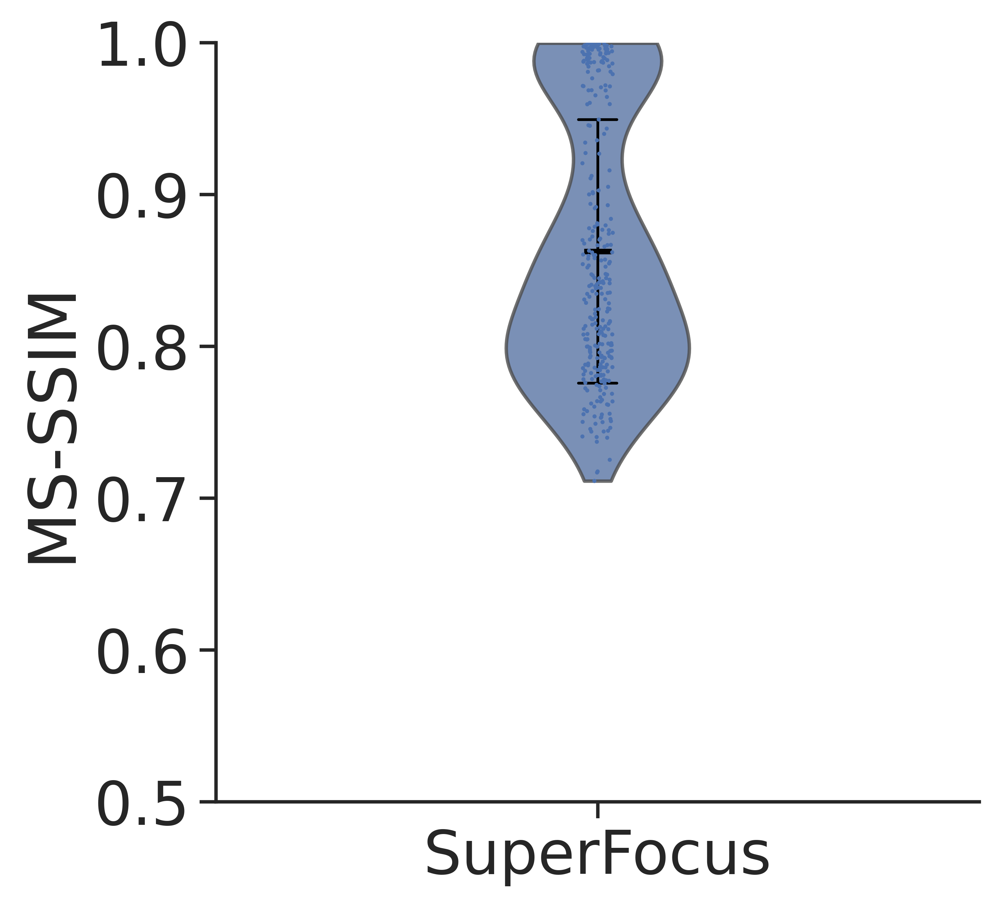

In [108]:
import seaborn as sns
sns.set(font="Arial")
sns.set_theme(style='ticks')
sns.set_context("notebook", font_scale=2)

columns = ['SuperFocus']
fig = plt.figure(figsize=(5,5), dpi=300)
ax = sns.violinplot(df[columns], inner=None, alpha=0.8, cut=0, gap=0.7)
sns.pointplot(data=df[columns], #x="day", y="total_bill", 
              estimator="mean", errorbar="sd", 
              linestyle="none", marker="_", color='black', capsize=0.05, err_kws={'linewidth': 1}, markersize=10)
sns.stripplot(df[columns], size=1.5, jitter=0.02, dodge=False, legend="", alpha=1, ax=ax)
plt.ylabel('MS-SSIM')
ax.set_ylim(0.5, 1)
ax.spines.right.set_color('none')
ax.spines.top.set_color('none')
for patch in ax.patches:
    r, g, b, a = patch.get_facecolor()
    patch.set_facecolor((r, g, b, .8))

#### NRMSE

In [114]:
from sklearn.metrics import root_mean_squared_error
import os
output_dir = "BreastCancer"
our_output_dir = os.path.join(output_dir, "SuperFocus_64")
xen_output_dir = os.path.join(output_dir, "Xenium_nongrid_64")

def get_rmse_norm(gene):
    xen_image_path = os.path.join(xen_output_dir, f'{gene}.png')
    superfocus_image_path = os.path.join(our_output_dir, f'{gene}.png')
    
    xen_image = np.array(Image.open(xen_image_path).convert('L'))
    superfocus_image = np.array(Image.open(superfocus_image_path).convert('L'))

    mean_xen = np.mean(xen_image)
    rmse_superfocus = root_mean_squared_error(superfocus_image, xen_image) /mean_xen
    
    return rmse_superfocus

df = pd.DataFrame(index=adata_sub.var_names, columns=['SuperFocus'])
for gene in adata_sub.var_names:
    df.loc[gene,  ['SuperFocus']] = get_rmse_norm(gene)

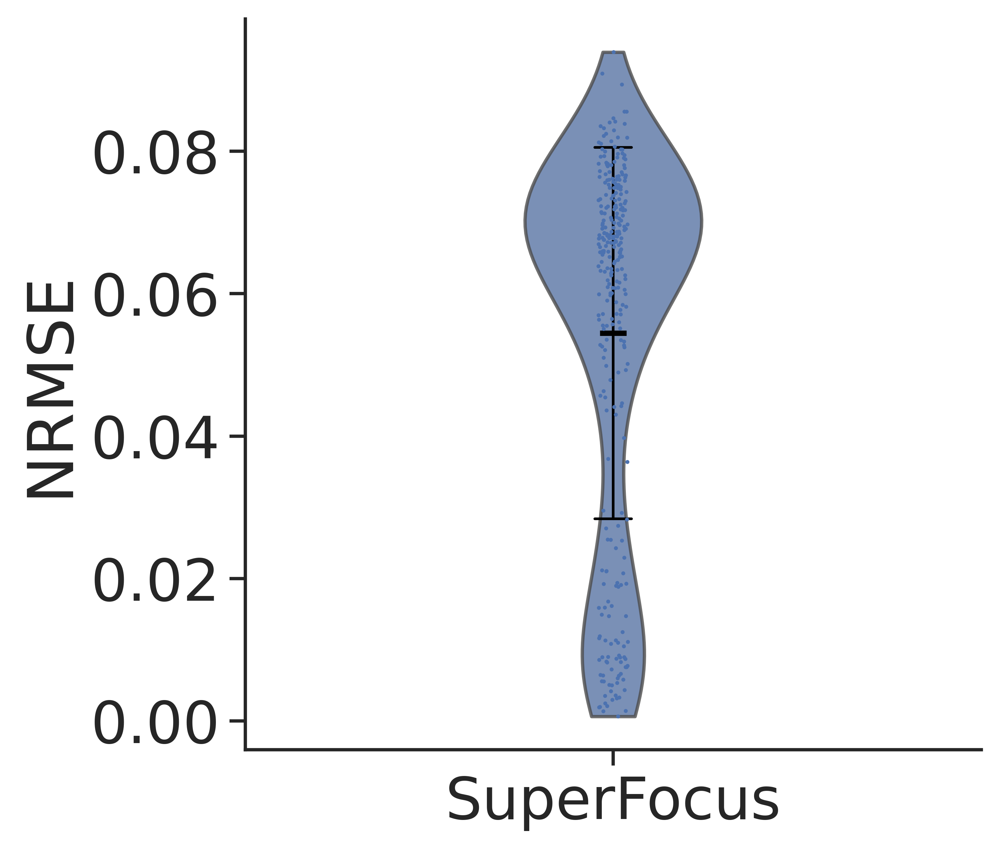

In [120]:
import seaborn as sns
sns.set(font="Arial")
sns.set_theme(style='ticks')
sns.set_context("notebook", font_scale=2)

columns = ['SuperFocus']
fig = plt.figure(figsize=(5,5), dpi=300)
ax = sns.violinplot(df[columns], inner=None, alpha=0.8, cut=0, gap=0.7)
sns.pointplot(data=df[columns], #x="day", y="total_bill", 
              estimator="mean", errorbar="sd", 
              linestyle="none", marker="_", color='black', capsize=0.05, err_kws={'linewidth': 1}, markersize=10)
sns.stripplot(df[columns], size=1.5, jitter=0.02, dodge=False, legend="", alpha=1, ax=ax)
plt.ylabel('NRMSE')
#ax.set_ylim(0, 0.15)
ax.spines.right.set_color('none')
ax.spines.top.set_color('none')
for patch in ax.patches:
    r, g, b, a = patch.get_facecolor()
    patch.set_facecolor((r, g, b, .8))